# Crude Oil Market & Inventory Forecasting — Model Evaluation

These notebooks contain the evaluation work for Sections 5.1 and 5.2.
The one-week-ahead inventory forecast is intentionally NOT included.

## 5.1 MAE, RMSE & Directional Accuracy

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Put this notebook inside your project/model-results folder, or change PROJECT below.
PROJECT = Path(".")

def find_file(name):
    matches = list(PROJECT.rglob(name))
    if not matches:
        raise FileNotFoundError(
            f"Could not find {name}. Put the model-results folder inside this notebook folder."
        )
    return matches[0]


In [2]:
# Load saved model metrics
lightgbm_metrics = pd.read_csv(find_file("lightgbm_metrics.csv"))
lstm_metrics = pd.read_csv(find_file("lstm_metrics.csv"))
sarimax_metrics = pd.read_csv(find_file("sarimax_metrics.csv"))

display(lightgbm_metrics)
display(lstm_metrics)
display(sarimax_metrics)


,Model,MAE (kb),RMSE (kb),R² Score,Directional Accuracy (%)
0,LightGBM (Standardized Target + Recency Weighted),3656.41,4677.17,0.0878,59.62


,Model,MAE (kb),RMSE (kb),R² Score,Directional Accuracy (%)
0,LSTM (PyTorch Regularized),3941.76,4910.4,-0.0055,50.96


,Model,MAE (kb),RMSE (kb),R² Score
0,"SARIMAX(2, 0, 2)",3701.87,4710.68,0.0747


In [3]:
# Load saved holdout predictions
lgbm_pred = pd.read_csv(find_file("lightgbm_predictions.csv"))
lstm_pred = pd.read_csv(find_file("lstm_predictions.csv"))
sarimax_pred = pd.read_csv(find_file("sarimax_forecast_holdout.csv"))

def directional_accuracy(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    return np.mean(np.sign(actual) == np.sign(predicted)) * 100

sarimax_da = directional_accuracy(
    sarimax_pred["target_next_week_change"],
    sarimax_pred["pred_sarimax"]
)
print(f"SARIMAX directional accuracy: {sarimax_da:.2f}%")


SARIMAX directional accuracy: 57.69%


In [4]:
evaluation = pd.DataFrame({
    "Model": ["SARIMAX", "SARIMAX + VIF-pruned", "LightGBM", "LSTM"],
    "MAE (kb)": [3701.87, 3711.21, 3656.41, 3941.76],
    "RMSE (kb)": [4710.68, 4770.73, 4677.17, 4910.40],
    "R²": [0.0747, 0.0509, 0.0878, -0.0055],
    "Directional Accuracy (%)": [sarimax_da, 57.69, 59.62, 50.96]
})
display(evaluation.round(2))


,Model,MAE (kb),RMSE (kb),R²,Directional Accuracy (%)
0,SARIMAX,3701.87,4710.68,0.07,57.69
1,SARIMAX + VIF-pruned,3711.21,4770.73,0.05,57.69
2,LightGBM,3656.41,4677.17,0.09,59.62
3,LSTM,3941.76,4910.40,-0.01,50.96


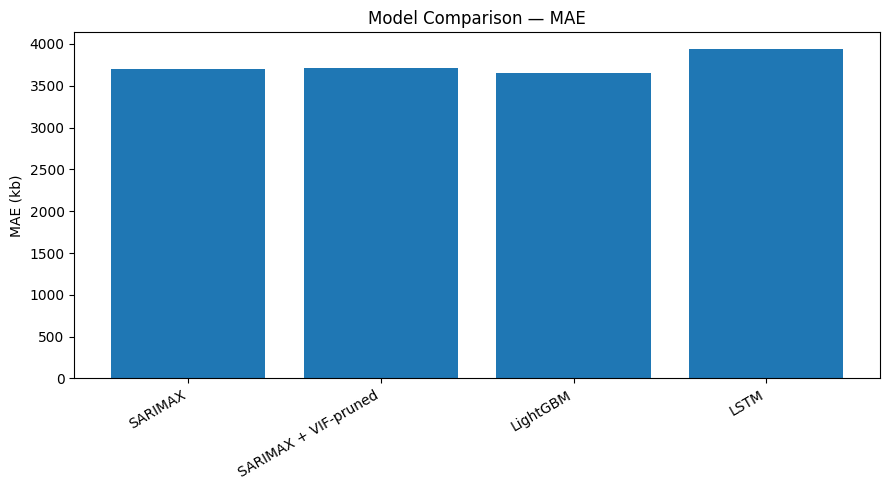

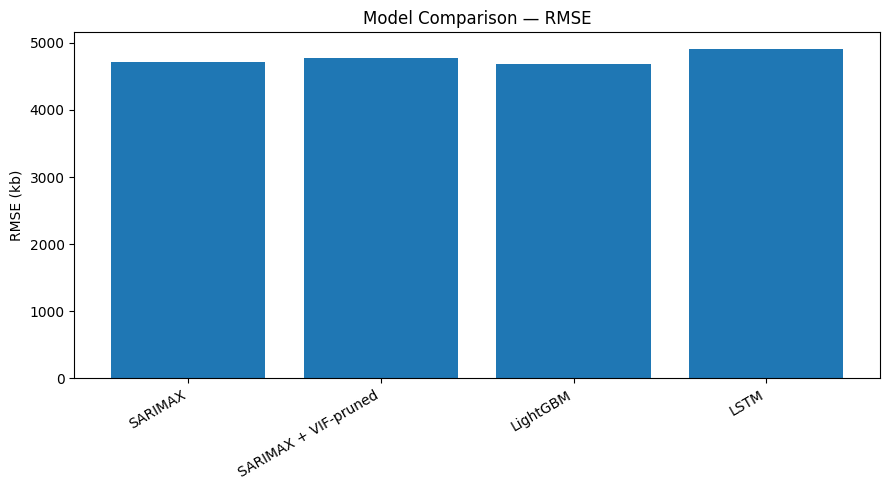

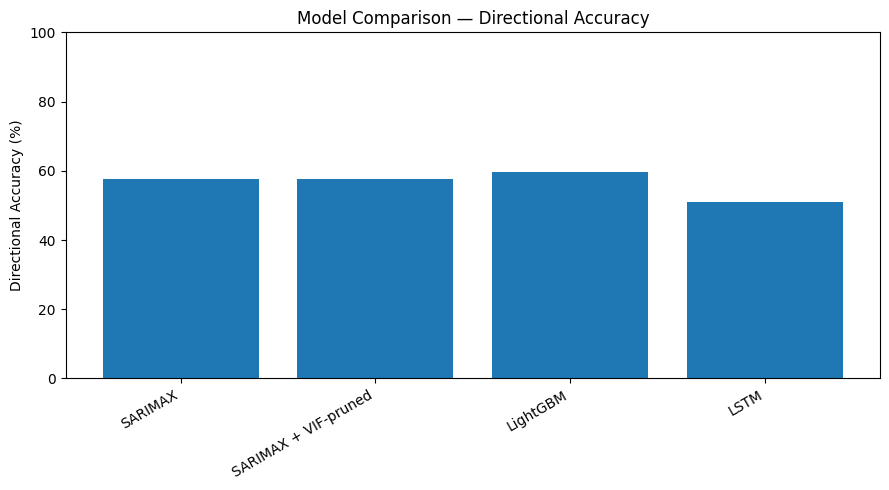

In [5]:
for metric, ylabel, title, ylim in [
    ("MAE (kb)", "MAE (kb)", "Model Comparison — MAE", None),
    ("RMSE (kb)", "RMSE (kb)", "Model Comparison — RMSE", None),
    ("Directional Accuracy (%)", "Directional Accuracy (%)", "Model Comparison — Directional Accuracy", (0,100))
]:
    plt.figure(figsize=(9,5))
    plt.bar(evaluation["Model"], evaluation[metric])
    plt.ylabel(ylabel)
    plt.title(title)
    if ylim: plt.ylim(*ylim)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


### Interpretation

MAE measures average absolute prediction error. RMSE gives greater weight to larger errors. R² measures explained variation relative to a mean-prediction baseline. Directional Accuracy measures how often the predicted and actual weekly inventory changes have the same sign.

LightGBM achieved MAE = **3,656.41 kb**, RMSE = **4,677.17 kb**, R² = **0.0878**, and Directional Accuracy = **59.62%** on the saved 104-week holdout period.


,Fold,Train_Size,Val_Size,MAE_kb,RMSE_kb,R2_Score,Directional_Acc_%
0,1,182,177,2826.478811,3575.567921,0.075155,58.757062
1,2,359,177,2984.241773,3747.250304,0.138879,63.841808
2,3,536,177,3621.270099,4624.188360,0.066252,67.796610
3,4,713,177,4637.029776,5834.539131,0.072007,58.757062
4,5,890,177,4026.010235,5130.580758,0.089566,63.276836


Mean MAE: 3619.01 kb
Mean RMSE: 4582.43 kb
Mean Directional Accuracy: 62.49%


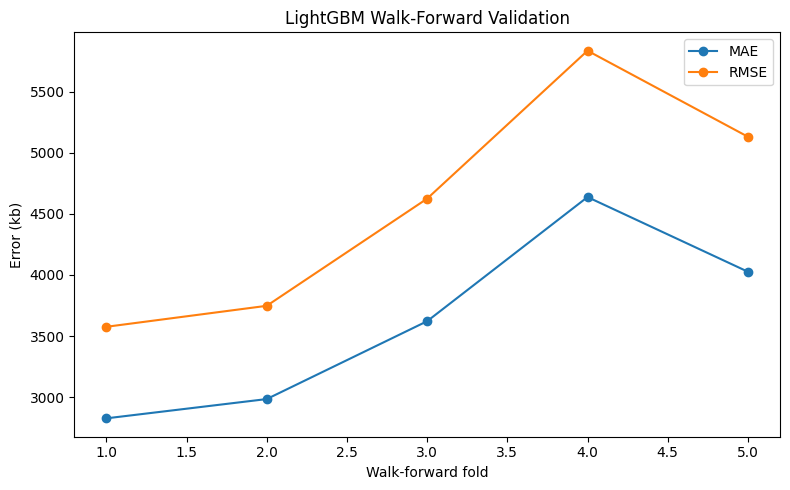

In [6]:
# Walk-forward LightGBM validation
wf = pd.read_csv(find_file("walk_forward_lightgbm_summary.csv"))
display(wf)

mae_col = "MAE_kb"
rmse_col = "RMSE_kb"
da_col = "Directional_Acc_%"

print(f"Mean MAE: {wf[mae_col].mean():.2f} kb")
print(f"Mean RMSE: {wf[rmse_col].mean():.2f} kb")
print(f"Mean Directional Accuracy: {wf[da_col].mean():.2f}%")

plt.figure(figsize=(8,5))
plt.plot(wf["Fold"], wf[mae_col], marker="o", label="MAE")
plt.plot(wf["Fold"], wf[rmse_col], marker="o", label="RMSE")
plt.xlabel("Walk-forward fold")
plt.ylabel("Error (kb)")
plt.title("LightGBM Walk-Forward Validation")
plt.legend()
plt.tight_layout()
plt.show()
